# M2-256 — Enhanced temporal-fusion Siamese U-Net at 256 × 256

This run evaluates the M2 architecture at 256 × 256 input resolution. Each complete 1024 × 1024 image and its label mask is resized to 256 × 256; the notebook does not extract patches. The additional decoder upsampling stage produces a mask at the same resolution as the resized label.

The temporal-fusion design and evaluation protocol are retained from M2. The run uses batch size 2 and mixed-float16 compute on a Google Colab NVIDIA T4 GPU, with a float32 output layer.

**Dataset split:** 445 training, 64 validation and 128 test image pairs.

## Resolution experiment

The architecture and evaluation protocol follow M2. The main experimental change is the input/output resolution: complete source images and masks are resized to 256 × 256. This is whole-image resizing, not patch extraction.

At this resolution, the decoder includes an additional upsampling stage so the predicted mask matches the target dimensions. The run uses mixed precision and batch size 2 on a T4 GPU.

## 1. Connect Google Drive and set the dataset location

Mount Google Drive, then set `DATASET_ROOT` to the directory containing the `train`, `val` and `test` folders. If the validation folder is named `valid`, update the corresponding entry in `SPLITS`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

# EDIT THIS to the directory containing train/, val/, and test/
DATASET_ROOT = "/content/drive/MyDrive/LEVIR-CD/LEVIR CD"

# Expected subfolder names
SPLITS = {
    "train": "train",
    "val": "val",
    "test": "test",
}

# Original source images are 1024x1024; resize each complete image to 256x256.
IMG_SIZE = 256
BATCH_SIZE = 2  # T4-safe starting point; reduce to 1 if GPU OOM occurs.
SEED = 42

import os
os.makedirs("/content/m2_checkpoints_256", exist_ok=True)

for split_name, folder in SPLITS.items():
    split_path = os.path.join(DATASET_ROOT, folder)
    assert os.path.isdir(split_path), f"Missing split folder: {split_path}"

print("Dataset root:", DATASET_ROOT)
print("Configured image size:", IMG_SIZE)
print("Configured batch size:", BATCH_SIZE)
print("GPU devices:", __import__("tensorflow").config.list_physical_devices("GPU"))


Mounted at /content/drive
Dataset root: /content/drive/MyDrive/LEVIR-CD/LEVIR CD
Configured image size: 256
Configured batch size: 2
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Imports and reproducibility

This section imports the libraries used for image loading, model construction, training and evaluation. The random seeds and runtime settings are defined here so the experiment can be repeated with the same configuration.

In [2]:
import os
import random
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models, mixed_precision
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Avoid TensorFlow reserving all GPU memory at startup.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# NVIDIA T4: use FP16 compute to reduce activation memory and improve throughput.
# Keep the model's final sigmoid output explicitly float32 (set in the model builder).
if tf.config.list_physical_devices("GPU"):
    mixed_precision.set_global_policy("mixed_float16")
    print("Mixed precision policy:", mixed_precision.global_policy())
else:
    print("No GPU detected; using the default float32 policy.")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision policy: <DTypePolicy "mixed_float16">


## 3. Match the before, after and label files

Image pairs are matched by filename stem across the `A`, `B` and `label` folders. The checks stop execution if a sample is missing from any folder, preventing unrelated files from being paired by list position.

In [3]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

def index_images(folder):
    folder = Path(folder)
    files = [
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]
    indexed = {}
    for path in files:
        key = path.stem
        if key in indexed:
            raise ValueError(f"Duplicate filename stem '{key}' in {folder}")
        indexed[key] = str(path)
    return indexed

def build_pairs(split_name):
    split_dir = os.path.join(DATASET_ROOT, SPLITS[split_name])
    a_map = index_images(os.path.join(split_dir, "A"))
    b_map = index_images(os.path.join(split_dir, "B"))
    y_map = index_images(os.path.join(split_dir, "label"))

    ids_a, ids_b, ids_y = set(a_map), set(b_map), set(y_map)
    if not (ids_a == ids_b == ids_y):
        raise ValueError(
            f"Filename mismatch in {split_name}: "
            f"A-only={sorted(ids_a-ids_b)[:5]}, "
            f"B-only={sorted(ids_b-ids_a)[:5]}, "
            f"label-missing={sorted(ids_a-ids_y)[:5]}, "
            f"label-only={sorted(ids_y-ids_a)[:5]}"
        )

    sample_ids = sorted(ids_a)
    pairs = [(a_map[k], b_map[k], y_map[k], k) for k in sample_ids]
    print(f"{split_name}: {len(pairs)} verified pairs")
    return pairs

train_pairs = build_pairs("train")
val_pairs = build_pairs("val")
test_pairs = build_pairs("test")

expected_counts = {"train": 445, "val": 64, "test": 128}
actual_counts = {
    "train": len(train_pairs),
    "val": len(val_pairs),
    "test": len(test_pairs),
}
print("Actual counts:", actual_counts)
for split, expected in expected_counts.items():
    if actual_counts[split] != expected:
        print(f"WARNING: {split} has {actual_counts[split]} pairs; "
              f"Kaggle description says {expected}. Check folder contents.")

train: 445 verified pairs
val: 64 verified pairs
test: 128 verified pairs
Actual counts: {'train': 445, 'val': 64, 'test': 128}


## 4. Load and preprocess the image pairs

The before and after images are converted to RGB and resized using area interpolation. Label masks use nearest-neighbour interpolation to preserve their binary values. ResNet50 preprocessing is applied in the input pipeline using the expected 0–255 pixel scale.

In [4]:
def read_rgb_image(path):
    image = cv2.imread(path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Could not read image: {path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(
        image, (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_AREA
    )
    return image.astype(np.uint8)

def read_binary_mask(path):
    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read mask: {path}")
    mask = cv2.resize(
        mask, (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_NEAREST
    )
    # LEVIR-CD masks are binary (typically 0 and 255).
    # Any non-zero label is treated as changed.
    mask = (mask > 0).astype(np.float32)
    return mask[..., np.newaxis]

def load_split(pairs, split_name):
    images_a, images_b, masks = [], [], []
    for path_a, path_b, path_mask, sample_id in pairs:
        images_a.append(read_rgb_image(path_a))
        images_b.append(read_rgb_image(path_b))
        masks.append(read_binary_mask(path_mask))

    X_a = np.stack(images_a).astype(np.uint8)
    X_b = np.stack(images_b).astype(np.uint8)
    Y = np.stack(masks).astype(np.float32)

    print(
        f"{split_name}: A={X_a.shape}, B={X_b.shape}, "
        f"mask={Y.shape}, mask values={np.unique(Y)}"
    )
    return X_a, X_b, Y

X1_train, X2_train, y_train = load_split(train_pairs, "train")
X1_val, X2_val, y_val = load_split(val_pairs, "validation")

# Test files are deliberately not loaded/evaluated until final testing.
print("Test pairs reserved:", len(test_pairs))

train: A=(445, 256, 256, 3), B=(445, 256, 256, 3), mask=(445, 256, 256, 1), mask values=[0. 1.]
validation: A=(64, 256, 256, 3), B=(64, 256, 256, 3), mask=(64, 256, 256, 1), mask values=[0. 1.]
Test pairs reserved: 128


## 5. Check sample alignment

The plots below show examples from the two dates and their reference change masks. Check that all three images refer to the same scene and that the mask marks the expected changed regions.

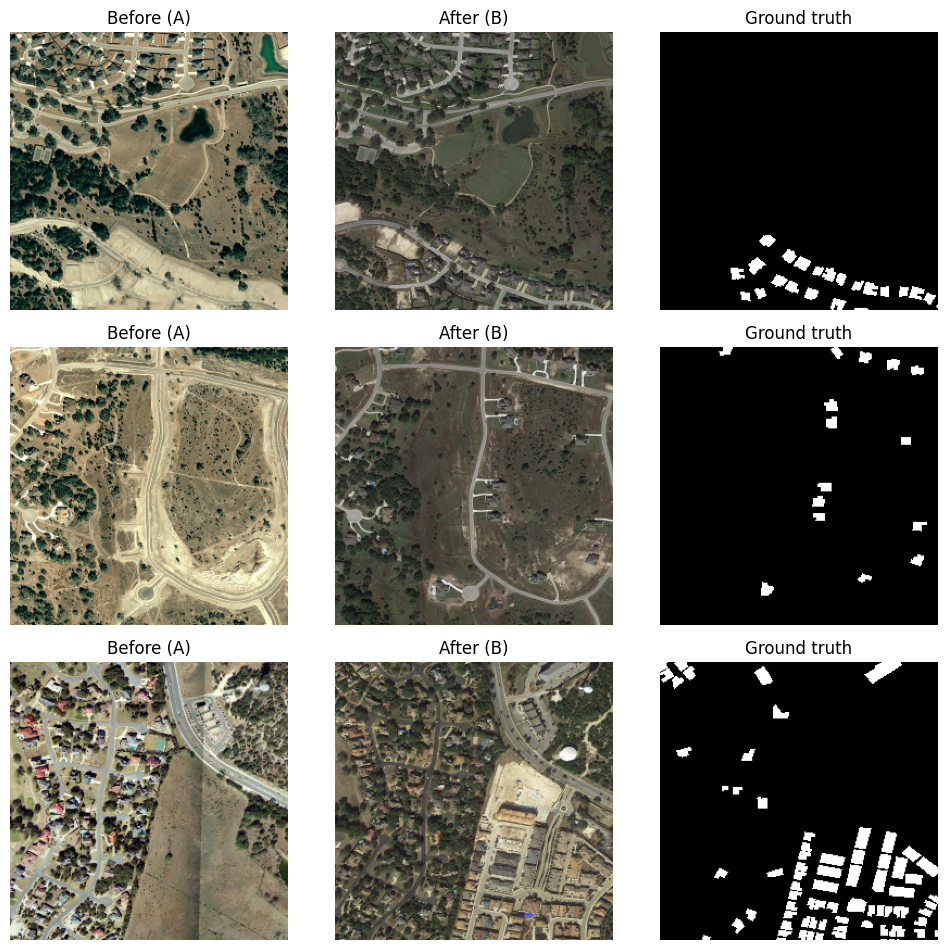

In [5]:
def show_samples(Xa, Xb, Y, n=3):
    n = min(n, len(Xa))
    fig, axes = plt.subplots(n, 3, figsize=(10, 3.2*n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)
    for i in range(n):
        axes[i, 0].imshow(Xa[i])
        axes[i, 0].set_title("Before (A)")
        axes[i, 1].imshow(Xb[i])
        axes[i, 1].set_title("After (B)")
        axes[i, 2].imshow(Y[i, ..., 0], cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title("Ground truth")
        for ax in axes[i]:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(X1_train, X2_train, y_train, n=3)

## 6. Prepare the TensorFlow datasets

The training pipeline applies the same spatial transformations to both dates and the label mask. Brightness changes, where enabled, are shared by the two dates. Validation and test samples are not augmented.

In [6]:
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_resnet_pair(image_a, image_b):
    # Inputs are RGB float tensors in the original 0..255 scale.
    image_a = tf.keras.applications.resnet50.preprocess_input(
        tf.cast(image_a, tf.float32)
    )
    image_b = tf.keras.applications.resnet50.preprocess_input(
        tf.cast(image_b, tf.float32)
    )
    return (image_a, image_b)

def augment_pair_tf(image_a, image_b, mask):
    # Cast images to float32 to perform brightness modifications safely
    image_a = tf.cast(image_a, tf.float32)
    image_b = tf.cast(image_b, tf.float32)
    mask = tf.cast(mask, tf.float32)

    # Synchronized horizontal and vertical flips.
    do_flip_lr = tf.random.uniform(()) > 0.5
    image_a = tf.cond(do_flip_lr, lambda: tf.image.flip_left_right(image_a), lambda: image_a)
    image_b = tf.cond(do_flip_lr, lambda: tf.image.flip_left_right(image_b), lambda: image_b)
    mask = tf.cond(do_flip_lr, lambda: tf.image.flip_left_right(mask), lambda: mask)

    do_flip_ud = tf.random.uniform(()) > 0.5
    image_a = tf.cond(do_flip_ud, lambda: tf.image.flip_up_down(image_a), lambda: image_a)
    image_b = tf.cond(do_flip_ud, lambda: tf.image.flip_up_down(image_b), lambda: image_b)
    mask = tf.cond(do_flip_ud, lambda: tf.image.flip_up_down(mask), lambda: mask)

    # Synchronized rotation by 0, 90, 180 or 270 degrees.
    k = tf.random.uniform((), minval=0, maxval=4, dtype=tf.int32)
    image_a = tf.image.rot90(image_a, k)
    image_b = tf.image.rot90(image_b, k)
    mask = tf.image.rot90(mask, k)

    # Same brightness multiplier for both dates.
    brightness_factor = tf.random.uniform((), 0.8, 1.2)
    image_a = tf.clip_by_value(image_a * brightness_factor, 0.0, 255.0)
    image_b = tf.clip_by_value(image_b * brightness_factor, 0.0, 255.0)

    return image_a, image_b, mask

def make_dataset(Xa, Xb, Y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((Xa, Xb, Y))
    if training:
        ds = ds.shuffle(
            buffer_size=len(Xa),
            seed=SEED,
            reshuffle_each_iteration=True
        )
        ds = ds.map(augment_pair_tf, num_parallel_calls=AUTOTUNE)

    ds = ds.map(
        lambda a, b, y: (preprocess_resnet_pair(a, b), y),
        num_parallel_calls=AUTOTUNE
    )
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    if not training:
        ds = ds.cache()
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(X1_train, X2_train, y_train, training=True)
val_ds = make_dataset(X1_val, X2_val, y_val, training=False)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

Training batches: 223
Validation batches: 32


## 7. Build M2: Siamese U-Net with enhanced temporal feature fusion

The shared ResNet50 encoder is unchanged. At each scale, M2 concatenates `feature_A`, `feature_B`, and `abs(feature_A - feature_B)`. A 1×1 convolution with Batch Normalization and ReLU compresses the concatenated channels to 32, 64, 128 and 256 channels respectively.

The decoder then upsamples these compact fused features through the same U-Net-style stages. This reduces the channel burden while allowing the decoder to use information from both dates, not only their absolute difference.

All preprocessing and training stages below are retained from M1 to keep the comparison controlled.

In [7]:
@tf.keras.utils.register_keras_serializable()
class AbsoluteDifference(layers.Layer):
    def call(self, inputs):
        return tf.abs(inputs[0] - inputs[1])

def project_temporal_features(feature_a, feature_b, scale_name, output_channels):
    """
    Fuse both temporal features and their absolute difference, then
    project the concatenated channels to a compact representation.
    """
    difference = AbsoluteDifference(name=f"{scale_name}_absolute_difference")(
        [feature_a, feature_b]
    )
    combined = layers.Concatenate(name=f"{scale_name}_temporal_concat")(
        [feature_a, feature_b, difference]
    )
    projected = layers.Conv2D(
        output_channels,
        kernel_size=1,
        padding="same",
        use_bias=False,
        name=f"{scale_name}_fusion_projection"
    )(combined)
    projected = layers.BatchNormalization(
        name=f"{scale_name}_fusion_bn"
    )(projected)
    projected = layers.Activation(
        "relu", name=f"{scale_name}_fusion_relu"
    )(projected)
    return projected

def build_m2_siamese_unet(input_shape=(IMG_SIZE, IMG_SIZE, 3)):
    input_a = layers.Input(shape=input_shape, name="image_before")
    input_b = layers.Input(shape=input_shape, name="image_after")

    resnet = tf.keras.applications.ResNet50(
        weights="imagenet",
        include_top=False,
        input_shape=input_shape
    )

    feature_layer_names = [
        "conv1_relu",          # 128 x 128 x 64 at 256x256 input
        "conv2_block3_out",    # 64 x 64 x 256
        "conv3_block4_out",    # 32 x 32 x 512
        "conv4_block6_out"     # 16 x 16 x 1024
    ]

    encoder = tf.keras.Model(
        inputs=resnet.input,
        outputs=[resnet.get_layer(name).output for name in feature_layer_names],
        name="shared_resnet50_encoder"
    )
    encoder.trainable = False

    features_a = encoder(input_a)
    features_b = encoder(input_b)

    # Projected fusion channels, shallow to deep.
    projection_channels = [32, 64, 128, 256]
    scale_names = ["scale_128", "scale_64", "scale_32", "scale_16"]

    fused_features = [
        project_temporal_features(fa, fb, name, channels)
        for fa, fb, name, channels in zip(
            features_a, features_b, scale_names, projection_channels
        )
    ]

    # Decoder: 16 -> 32 -> 64 -> 128 -> 256.
    # M2 uses compact projected fusion maps as multi-scale skip features.
    x = fused_features[3]  # 16 x 16 x 256

    x = layers.UpSampling2D(interpolation="nearest", name="up_to_32")(x)
    x = layers.Concatenate(name="decoder_concat_32")([x, fused_features[2]])
    x = layers.Conv2D(256, 3, padding="same", activation="relu",
                      name="decoder_conv_32")(x)

    x = layers.UpSampling2D(interpolation="nearest", name="up_to_64")(x)
    x = layers.Concatenate(name="decoder_concat_64")([x, fused_features[1]])
    x = layers.Conv2D(128, 3, padding="same", activation="relu",
                      name="decoder_conv_64")(x)

    x = layers.UpSampling2D(interpolation="nearest", name="up_to_128")(x)
    x = layers.Concatenate(name="decoder_concat_128")([x, fused_features[0]])
    x = layers.Conv2D(64, 3, padding="same", activation="relu",
                      name="decoder_conv_128")(x)

    x = layers.UpSampling2D(interpolation="nearest", name="up_to_256")(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu",
                      name="decoder_conv_256")(x)

    output = layers.Conv2D(
        1, 1, activation="sigmoid", dtype="float32",
        name="change_probability"
    )(x)

    model = models.Model(
        [input_a, input_b], output,
        name="M2_Enhanced_Temporal_Fusion_Siamese_UNet"
    )
    return model, encoder

model, encoder = build_m2_siamese_unet()
model.summary()

print("\nM2 fusion projection outputs:")
for layer_name in [
    "scale_128_fusion_relu",
    "scale_64_fusion_relu",
    "scale_32_fusion_relu",
    "scale_16_fusion_relu"
]:
    print(layer_name, model.get_layer(layer_name).output.shape)

# Sanity checks: model output must match the 256x256 ground-truth mask.
assert model.input_shape[0][1:] == (IMG_SIZE, IMG_SIZE, 3)
assert model.output_shape[1:] == (IMG_SIZE, IMG_SIZE, 1), model.output_shape
print("Verified model output shape:", model.output_shape)


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "M2_Enhanced_Temporal_Fusion_Siamese_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_before        │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_after         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ shared_resnet50_en… │ [(None, 128, 128, │  8,589,184 │ image_before[0][… │
│ (Functional)        │ 64), (None, 64,   │            │ image_after[0][0] │
│                     │ 64, 256), (None,  │            │                   │
│                     │ 32, 32, 512),     │            │                   │
│                     │ (None, 16, 16,    │            │                   │
│                     │ 1024)]            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_16_absolute_… │ (None, 16, 16,    │          0 │ shared_resnet50_… │
│ (AbsoluteDifferenc… │ 1024)             │            │ shared_resnet50_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_16_temporal_… │ (None, 16, 16,    │          0 │ shared_resnet50_… │
│ (Concatenate)       │ 3072)             │            │ shared_resnet50_… │
│                     │                   │            │ scale_16_absolut… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_32_absolute_… │ (None, 32, 32,    │          0 │ shared_resnet50_… │
│ (AbsoluteDifferenc… │ 512)              │            │ shared_resnet50_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_16_fusion_pr… │ (None, 16, 16,    │    786,432 │ scale_16_tempora… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_32_temporal_… │ (None, 32, 32,    │          0 │ shared_resnet50_… │
│ (Concatenate)       │ 1536)             │            │ shared_resnet50_… │
│                     │                   │            │ scale_32_absolut… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_16_fusion_bn  │ (None, 16, 16,    │      1,024 │ scale_16_fusion_… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_32_fusion_pr… │ (None, 32, 32,    │    196,608 │ scale_32_tempora… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_16_fusion_re… │ (None, 16, 16,    │          0 │ scale_16_fusion_… │
│ (Activation)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_32_fusion_bn  │ (None, 32, 32,    │        512 │ scale_32_fusion_… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_64_absolute_… │ (None, 64, 64,    │          0 │ shared_resnet50_… │
│ (AbsoluteDifferenc… │ 256)              │            │ shared_resnet50_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_to_32            │ (None, 32, 32,    │          0 │ scale_16_fusion_… │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ scale_32_fusion_re… │ (None, 32, 32,    │          0 │ scale_32_fusion_

 Total params: 10,993,921 (41.94 MB)

 Trainable params: 2,403,777 (9.17 MB)

 Non-trainable params: 8,590,144 (32.77 MB)


M2 fusion projection outputs:
scale_128_fusion_relu (None, 128, 128, 32)
scale_64_fusion_relu (None, 64, 64, 64)
scale_32_fusion_relu (None, 32, 32, 128)
scale_16_fusion_relu (None, 16, 16, 256)
Verified model output shape: (None, 256, 256, 1)


## 8. Loss function and metrics

This section defines the training loss and the metrics used to monitor segmentation performance. The reported test metrics are calculated separately using the validation-selected probability threshold.

In [8]:
def dice_loss(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    axes = [1, 2, 3]
    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    denominator = (
        tf.reduce_sum(y_true, axis=axes) +
        tf.reduce_sum(y_pred, axis=axes)
    )
    dice = (2.0 * intersection + smooth) / (denominator + smooth)
    return 1.0 - tf.reduce_mean(dice)

def combined_loss(y_true, y_pred):
    bce = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(y_true, y_pred)
    )
    return bce + dice_loss(y_true, y_pred)

def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=combined_loss,
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="binary_accuracy", threshold=0.5),
            tf.keras.metrics.Precision(name="precision", thresholds=0.5),
            tf.keras.metrics.Recall(name="recall", thresholds=0.5),
            tf.keras.metrics.BinaryIoU(
                target_class_ids=[1], threshold=0.5, name="change_iou"
            )
        ]
    )

compile_model(model, learning_rate=1e-4)

## 9. Stage 1 — train the decoder

The encoder is frozen during the first stage, while the decoder and fusion layers are trained. The best checkpoint is selected using validation loss.

In [9]:
import time

class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.training_start = time.perf_counter()
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.perf_counter() - self.epoch_start
        self.epoch_times.append(elapsed)
        print(f"Epoch {epoch + 1} duration: {elapsed:.1f} sec")

    def on_train_end(self, logs=None):
        total = time.perf_counter() - self.training_start
        print(f"Total fit duration: {total / 60:.2f} min")


In [10]:
STAGE1_EPOCHS = 8
stage1_weights = "/content/m2_checkpoints_256/m2_stage1_best.weights.h5"

stage1_timer = EpochTimer()
stage1_callbacks = [
    stage1_timer,
    tf.keras.callbacks.ModelCheckpoint(
        stage1_weights,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    )
]

history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=STAGE1_EPOCHS,
    callbacks=stage1_callbacks,
    verbose=1
)

model.load_weights(stage1_weights)
print("Restored best Stage 1 weights.")

Epoch 1/8
223/223 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - binary_accuracy: 0.9455 - change_iou: 0.1574 - loss: 1.0150 - precision: 0.3092 - recall: 0.2409Epoch 1 duration: 96.1 sec

Epoch 1: val_loss improved from None to 0.83406, saving model to /content/m2_checkpoints_256/m2_stage1_best.weights.h5

Epoch 1: finished saving model to /content/m2_checkpoints_256/m2_stage1_best.weights.h5
223/223 ━━━━━━━━━━━━━━━━━━━━ 97s 211ms/step - binary_accuracy: 0.9463 - change_iou: 0.2588 - loss: 0.9016 - precision: 0.4141 - recall: 0.4083 - val_binary_accuracy: 0.9669 - val_change_iou: 0.3089 - val_loss: 0.8341 - val_precision: 0.7140 - val_recall: 0.3525 - learning_rate: 1.0000e-04
Epoch 2/8
221/223 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - binary_accuracy: 0.9551 - change_iou: 0.3923 - loss: 0.7467 - precision: 0.5605 - recall: 0.5700Epoch 2 duration: 66.4 sec

Epoch 2: val_loss improved from 0.83406 to 0.71607, saving model to /content/m2_checkpoints_256/m2_stage1_best.weights.h5

Epoch 2: finished savi

## 10. Stage 2 — fine-tune the encoder

The selected convolutional layers in the final ResNet50 stage are unfrozen for fine-tuning. Batch Normalization layers remain frozen, and a lower learning rate is used for this stage.

In [11]:
# Unfreeze only convolutional layers in the ResNet conv4 stage.
encoder.trainable = True
for layer in encoder.layers:
    if layer.name.startswith("conv4_") and not isinstance(
        layer, tf.keras.layers.BatchNormalization
    ):
        layer.trainable = True
    else:
        layer.trainable = False

trainable_encoder_layers = [
    layer.name for layer in encoder.layers if layer.trainable
]
print("Trainable encoder layers:", len(trainable_encoder_layers))
print(trainable_encoder_layers[:10])

# Recompile after changing trainable flags.
compile_model(model, learning_rate=1e-5)

STAGE2_EPOCHS = 40
stage2_weights = "/content/m2_checkpoints_256/m2_stage2_best.weights.h5"

stage2_timer = EpochTimer()
stage2_callbacks = [
    stage2_timer,
    tf.keras.callbacks.ModelCheckpoint(
        stage2_weights,
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

history_stage2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=STAGE2_EPOCHS,
    callbacks=stage2_callbacks,
    verbose=1
)

model.load_weights(stage2_weights)
print("Restored best Stage 2 weights.")

Trainable encoder layers: 43
['conv4_block1_1_conv', 'conv4_block1_1_relu', 'conv4_block1_2_conv', 'conv4_block1_2_relu', 'conv4_block1_0_conv', 'conv4_block1_3_conv', 'conv4_block1_add', 'conv4_block1_out', 'conv4_block2_1_conv', 'conv4_block2_1_relu']
Epoch 1/40
223/223 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - binary_accuracy: 0.9771 - change_iou: 0.5678 - loss: 0.5180 - precision: 0.7422 - recall: 0.7078Epoch 1 duration: 80.8 sec

Epoch 1: val_loss improved from None to 0.59893, saving model to /content/m2_checkpoints_256/m2_stage2_best.weights.h5

Epoch 1: finished saving model to /content/m2_checkpoints_256/m2_stage2_best.weights.h5
223/223 ━━━━━━━━━━━━━━━━━━━━ 82s 181ms/step - binary_accuracy: 0.9755 - change_iou: 0.5722 - loss: 0.5228 - precision: 0.7431 - recall: 0.7132 - val_binary_accuracy: 0.9773 - val_change_iou: 0.5725 - val_loss: 0.5989 - val_precision: 0.7325 - val_recall: 0.7239 - learning_rate: 1.0000e-05
Epoch 2/40
222/223 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - binary_accura

## 11. Select the checkpoint using validation data

Stage 1 and Stage 2 checkpoints are compared on the validation set. The checkpoint with the lower validation loss is retained for threshold selection and final evaluation.

In [12]:
# Evaluate Stage 2 checkpoint.
model.load_weights(stage2_weights)
stage2_val_loss = float(model.evaluate(val_ds, verbose=0)[0])

# Evaluate Stage 1 checkpoint.
model.load_weights(stage1_weights)
stage1_val_loss = float(model.evaluate(val_ds, verbose=0)[0])

if stage2_val_loss <= stage1_val_loss:
    model.load_weights(stage2_weights)
    selected_stage = "Stage 2 (fine-tuned encoder)"
    selected_val_loss = stage2_val_loss
else:
    model.load_weights(stage1_weights)
    selected_stage = "Stage 1 (frozen encoder)"
    selected_val_loss = stage1_val_loss

print("Stage 1 validation loss:", stage1_val_loss)
print("Stage 2 validation loss:", stage2_val_loss)
print("Selected checkpoint:", selected_stage)
print("Selected validation loss:", selected_val_loss)

FINAL_MODEL_PATH = "/content/m2_checkpoints_256/M2_EnhancedFusion_Siamese_UNet_256.keras"
model.save(FINAL_MODEL_PATH)
print("Saved model:", FINAL_MODEL_PATH)

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'loss_scale_optimizer', because it has 126 variables whereas the saved optimizer has 50 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 122 variables whereas the saved optimizer has 46 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Stage 1 validation loss: 0.602134644985199
Stage 2 validation loss: 0.5567951202392578
Selected checkpoint: Stage 2 (fine-tuned encoder)
Selected validation loss: 0.5567951202392578
Saved model: /content/m2_checkpoints_256/M2_EnhancedFusion_Siamese_UNet_256.keras


## 12. Training history

The plots show the training and validation curves for each stage. They provide a view of convergence and any gap between training and validation performance.

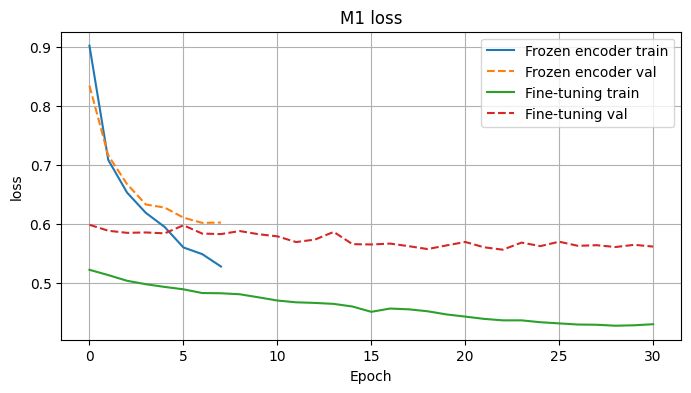

In [13]:
def plot_histories(*histories, labels=None, metric="loss"):
    plt.figure(figsize=(8, 4))
    for i, hist in enumerate(histories):
        label = labels[i] if labels else f"Stage {i+1}"
        if metric in hist.history:
            plt.plot(hist.history[metric], label=f"{label} train")
        val_key = "val_" + metric
        if val_key in hist.history:
            plt.plot(hist.history[val_key], linestyle="--", label=f"{label} val")
    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(f"M1 {metric}")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_histories(history_stage1, history_stage2,
               labels=["Frozen encoder", "Fine-tuning"], metric="loss")

## 13. Choose the probability threshold on validation data

The threshold is selected from validation predictions using the predefined threshold grid and F1 score. The selected value is then fixed before the test set is evaluated.

In [14]:
def predict_dataset(model, dataset):
    return model.predict(dataset, verbose=1)

val_probs = predict_dataset(model, val_ds)

def binary_metrics(y_true, y_prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(np.uint8).reshape(-1)
    y_pred = (np.asarray(y_prob).reshape(-1) >= threshold).astype(np.uint8)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    iou = tp / max(tp + fp + fn, 1)
    dice = 2 * tp / max(2 * tp + fp + fn, 1)

    return {
        "threshold": float(threshold),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "iou": iou,
        "dice": dice,
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)
    }

thresholds = np.arange(0.05, 0.96, 0.05)
val_rows = [
    binary_metrics(y_val, val_probs, threshold=t)
    for t in thresholds
]
val_threshold_table = pd.DataFrame(val_rows)
display(val_threshold_table)

best_idx = val_threshold_table["f1"].idxmax()
BEST_THRESHOLD = float(val_threshold_table.loc[best_idx, "threshold"])
print("Selected validation threshold:", BEST_THRESHOLD)
print("Validation metrics at selected threshold:")
display(pd.DataFrame([val_rows[best_idx]]))

32/32 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step


,threshold,accuracy,precision,recall,f1,iou,dice,tp,fp,fn,tn
0,0.05,0.967741,0.574883,0.887702,0.697840,0.535909,0.697840,156240,115537,19765,3902762
1,0.10,0.971757,0.616732,0.863691,0.719613,0.562028,0.719613,152014,94469,23991,3923830
2,0.15,0.973764,0.642125,0.846646,0.730337,0.575221,0.730337,149014,83050,26991,3935249
3,0.20,0.975088,0.661137,0.833562,0.737404,0.584038,0.737404,146711,75196,29294,3943103
4,0.25,0.976037,0.676597,0.821704,0.742124,0.589982,0.742124,144624,69128,31381,3949171
5,0.30,0.976773,0.689800,0.811346,0.745652,0.594454,0.745652,142801,64217,33204,3954082
6,0.35,0.977349,0.701455,0.801210,0.748021,0.597471,0.748021,141017,60018,34988,3958281
7,0.40,0.977863,0.712835,0.791188,0.749970,0.599962,0.749970,139253,56098,36752,3962201
8,0.45,0.978290,0.723453,0.781290,0.751260,0.601614,0.751260,137511,52565,38494,3965734
9,0.50,0.978640,0.733526,0.771114,0.751851,0.602373,0.751851,135720,49304,40285,3968995


Selected validation threshold: 0.55
Validation metrics at selected threshold:


,threshold,accuracy,precision,recall,f1,iou,dice,tp,fp,fn,tn
0,0.55,0.978954,0.7437,0.760581,0.752046,0.602623,0.752046,133866,46134,42139,3972165


## 14. Evaluate on the held-out test set

The selected checkpoint and fixed threshold are applied to the test split. These results are the final evaluation for this run; the test labels are not used to adjust model settings.

In [15]:
X1_test, X2_test, y_test = load_split(test_pairs, "test")
test_ds = make_dataset(X1_test, X2_test, y_test, training=False)

test_probs = predict_dataset(model, test_ds)
test_results = binary_metrics(y_test, test_probs, threshold=BEST_THRESHOLD)

print("M2 FINAL TEST RESULTS")
display(pd.DataFrame([test_results]))

test: A=(128, 256, 256, 3), B=(128, 256, 256, 3), mask=(128, 256, 256, 1), mask values=[0. 1.]
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step
M2 FINAL TEST RESULTS


,threshold,accuracy,precision,recall,f1,iou,dice,tp,fp,fn,tn
0,0.55,0.973457,0.733762,0.751507,0.742529,0.590494,0.742529,321068,116496,106164,7844880


## 15. Inspect predicted change masks

The visualizations compare the input images, reference mask and model prediction. They are included to complement the numerical metrics and show examples of missed and incorrectly detected changes.

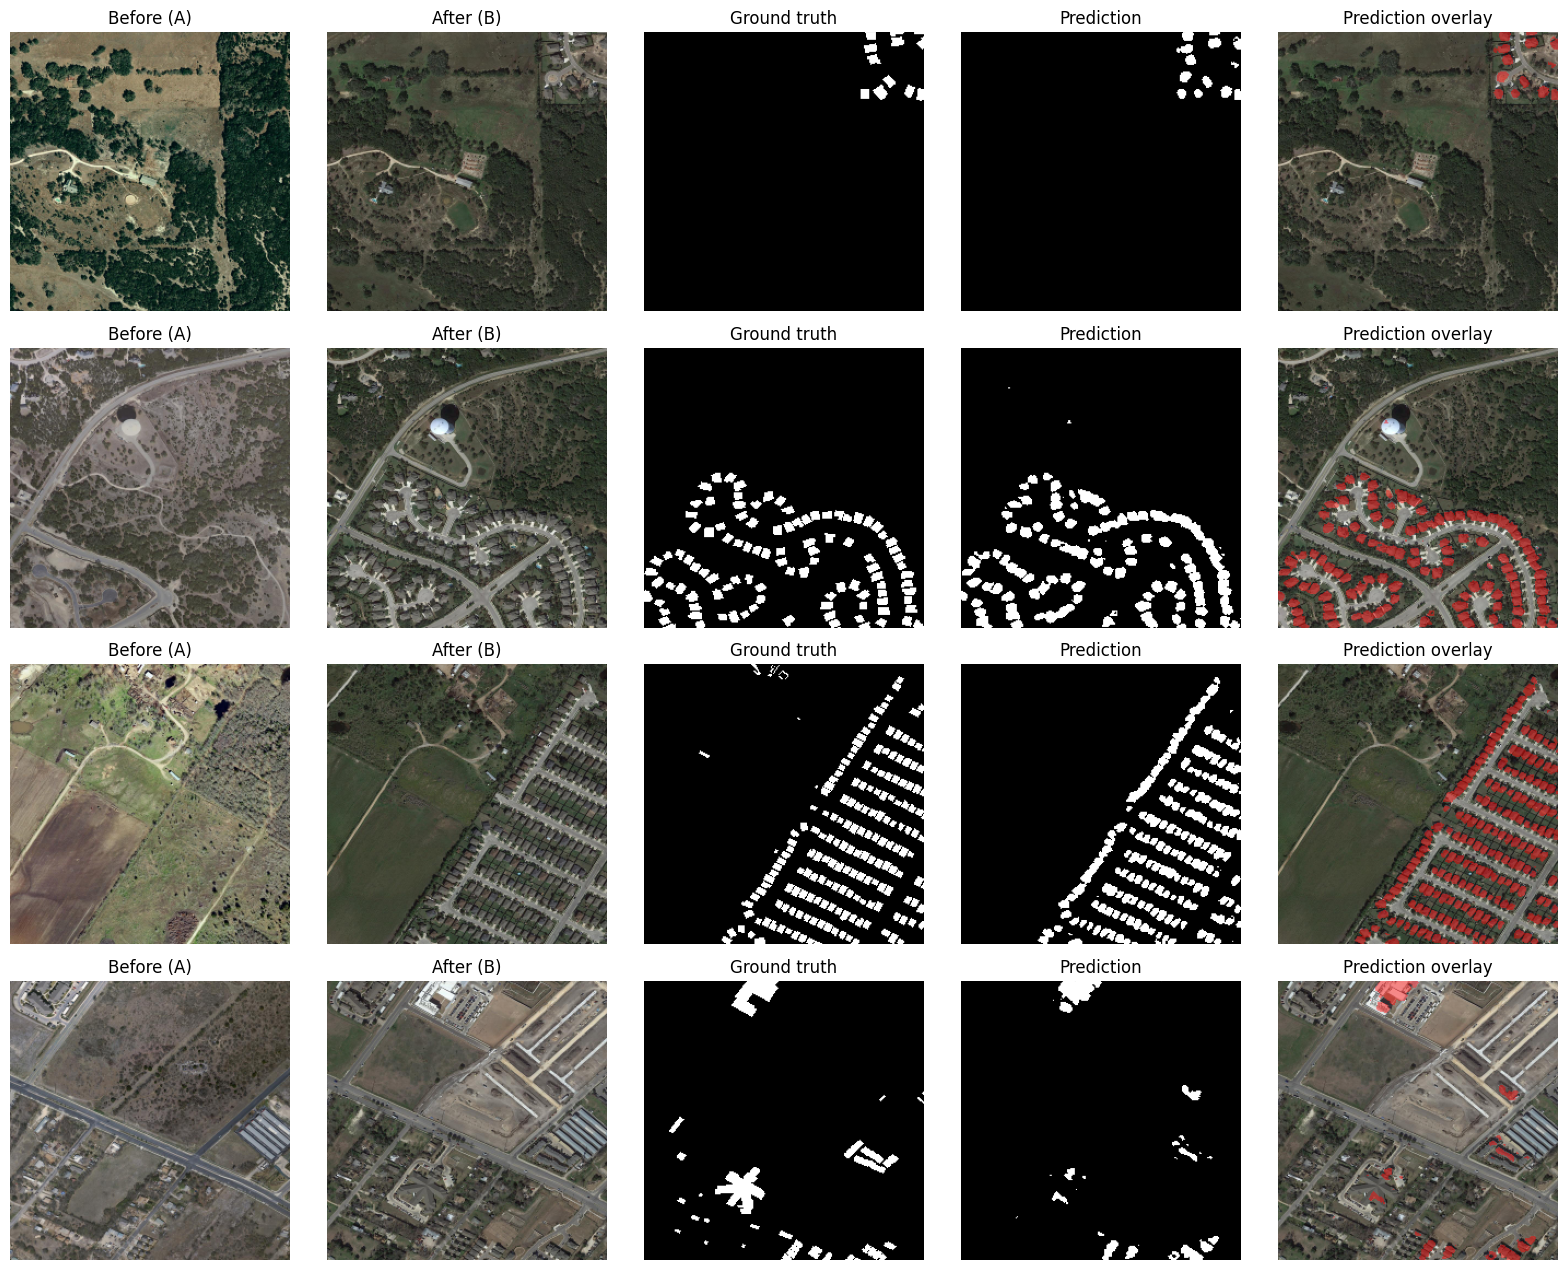

In [16]:
def visualize_predictions(Xa, Xb, Y, probabilities, threshold, indices=None, n=4):
    if indices is None:
        indices = list(range(min(n, len(Xa))))
    fig, axes = plt.subplots(len(indices), 5, figsize=(16, 3.2*len(indices)))
    if len(indices) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, idx in enumerate(indices):
        pred = (probabilities[idx, ..., 0] >= threshold).astype(np.uint8)
        gt = Y[idx, ..., 0]

        overlay = Xb[idx].copy()
        changed = pred == 1
        # Highlight predicted changes in red.
        overlay[changed] = (
            0.55 * overlay[changed] + 0.45 * np.array([255, 0, 0])
        ).astype(np.uint8)

        panels = [
            (Xa[idx], "Before (A)", None),
            (Xb[idx], "After (B)", None),
            (gt, "Ground truth", "gray"),
            (pred, "Prediction", "gray"),
            (overlay, "Prediction overlay", None)
        ]
        for col, (image, title, cmap) in enumerate(panels):
            axes[row, col].imshow(image, cmap=cmap, vmin=0, vmax=1 if cmap else None)
            axes[row, col].set_title(title)
            axes[row, col].axis("off")

    plt.tight_layout()
    plt.show()

visualize_predictions(
    X1_test, X2_test, y_test, test_probs,
    BEST_THRESHOLD, indices=[0, 1, 2, 3]
)

## 16. Save the model and evaluation results

The final cell saves the trained model and the evaluation files to the experiment-specific Google Drive directory.

In [17]:
import shutil

DRIVE_OUTPUT = "/content/drive/MyDrive/LEVIR-CD_M2_outputs"
os.makedirs(DRIVE_OUTPUT, exist_ok=True)

shutil.copy2(FINAL_MODEL_PATH, os.path.join(DRIVE_OUTPUT, "M2_EnhancedFusion_Siamese_UNet_256.keras"))
pd.DataFrame([test_results]).to_csv(
    os.path.join(DRIVE_OUTPUT, "M2_256_test_metrics.csv"), index=False
)
val_threshold_table.to_csv(
    os.path.join(DRIVE_OUTPUT, "M2_256_validation_thresholds.csv"), index=False
)

print("Saved M2 model and results to:", DRIVE_OUTPUT)

Saved M2 model and results to: /content/drive/MyDrive/LEVIR-CD_M2_outputs


## Experiment summary

This run evaluates the M2 architecture at 256 × 256 using full-image resizing. The decoder output is also 256 × 256. The saved test metrics are summarized below.

## M2 resolution comparison

The results below are taken from the two saved 256 × 256 evaluation runs and the earlier 128 × 128 experiments.

| Run | Input size | Threshold | Test F1 | Test IoU |
|---|---:|---:|---:|---:|
| M1 baseline | 128 × 128 | 0.40 | 52.56% | 35.64% |
| M2 | 128 × 128 | 0.40 | 61.55% | 44.46% |
| M2-256, seed 42 run | 256 × 256 | 0.55 | 74.25% | 59.05% |
| M2-256, seed 43 run | 256 × 256 | 0.45 | 74.35% | 59.17% |

The 256 × 256 runs score higher in this evaluation. Since the resolution and training run differ from the 128 × 128 baseline, the result should be described as an observed comparison rather than attributed to resolution alone.